# Somatotopic Decoding — Linear SVC

**Task:** S1Map | **ROI:** Left S1 (Destrieux G_postcentral)  
**Classes:** Middle_Finger · Hand · Forearm · Arm (4-way, imbalanced)  
**Cross-validation:** Leave-One-Run-Out (LORO, 4 folds)  
**Classifier:** LinearSVC (C=3.0, OVR, `class_weight='balanced'`)  
**Features:** ROI BOLD averaged in a ±1-volume window around the HRF peak (~6 s delay)


In [25]:
# 1. Load the extension
%load_ext autoreload

# 2. Set it to mode 2 (reload all modules every time a cell is executed)
%autoreload 2

import numpy as np
import pandas as pd

# Initialize random number generator for reproducibility.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
# Electrode-to-region mapping (20 electrodes → 4 body regions)
REGION_TO_ELECTRODES = {
    'Middle_Finger': ['E1', 'E2', 'E3'],
    'Hand':          ['E4', 'E5', 'E6', 'E7'],
    'Forearm':       ['E8', 'E9', 'E10', 'E11', 'E12', 'E13'],
    'Arm':           ['E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20'],
}

    
ELECTRODE_TO_REGION = {
    electrode: region
    for region, electrodes in REGION_TO_ELECTRODES.items()
    for electrode in electrodes
}


In [27]:
# save file demonstrating the mapping from electrodes to body regions
mapping_df = pd.DataFrame(list(ELECTRODE_TO_REGION.items()), columns=['Electrode', 'Body_Region'])
mapping_df.to_csv('electrode_to_body_region_mapping.csv', index=False)

In [28]:
# BIDS dataset paths and experiment parameters
from pathlib import Path
import json


BIDS_ROOT = Path(r"/Volumes/T7/datasets/BIDS-somatosensory").resolve()

DERIVATIVES = BIDS_ROOT / "derivatives" / "fmriprep"

session            = "01"
task               = "S1Map"
space              = "MNI152NLin2009cAsym"
n_runs_per_subject = 4

HRF_DELAY = 6.0  # seconds from stimulus onset to HRF peak
WINDOW    = 1    # volumes to average on each side of the peak

## 1. Data Indexing (BIDS Integration)

In [29]:
import re

# Get the list of subjects that have derivatives and events files
derivative_subjects = sorted(d.name for d in DERIVATIVES.iterdir() if d.is_dir() and d.name.startswith("sub-"))

# Get the list of subjects that have events files
event_subjects = set()

for ev_path in BIDS_ROOT.rglob(f"sub-*_ses-{session}_task-{task}_run-*_events.tsv"):
    m = re.match(r"^(sub-[^_]+)_", ev_path.name)
    if m:
        event_subjects.add(m.group(1))

event_subjects = sorted(event_subjects)

subjects = sorted(set(derivative_subjects) & set(event_subjects))

print(f"Subjects in derivatives: {len(derivative_subjects)}")
print(f"Subjects in events:      {len(event_subjects)}")
print(f"Subjects included:       {len(subjects)}")
print(subjects)

Subjects in derivatives: 2
Subjects in events:      2
Subjects included:       2
['sub-p0001', 'sub-p0002']


In [30]:
# Function to get the TR (Repetition Time) for a given subject and run.
def get_tr(subject, run=1, default_tr=2.0):

    # Construct the path to the functional directory for the subject and session.
    func_dir = DERIVATIVES / f"{subject}/ses-{session}/func"

    # Construct the expected JSON filenames for the BOLD data.
    json_candidates = [
        func_dir / f"{subject}_ses-{session}_task-{task}_run-{run}_space-{space}_desc-preproc_bold.json",
        func_dir / f"{subject}_ses-{session}_task-{task}_run-{run}_desc-preproc_bold.json",
    ]

    # Check each candidate JSON file for the RepetitionTime field.
    for bold_json in json_candidates:
        # print(f"Checking for TR JSON: {bold_json}")
        if bold_json.exists():

            # Read the JSON file and extract the RepetitionTime.
            with open(bold_json, "r", encoding="utf-8") as f:
                meta = json.load(f)

            # Check if RepetitionTime is present and return it.
            if "RepetitionTime" in meta and meta["RepetitionTime"] is not None:
                return float(meta["RepetitionTime"])

            print(
                f"Warning: RepetitionTime missing in {bold_json.name} for {subject}. "
                f"Using default TR={default_tr} s."
            )
            
            return float(default_tr)

    print(
        f"Warning: No TR JSON found for {subject} (run {run}). "
        f"Using default TR={default_tr} s."
    )
    return float(default_tr)


# Get TR for each subject.
tr_by_subject = {sub: get_tr(sub, run=1, default_tr=2.0) for sub in subjects}

# Check if TR is consistent across subjects.
unique_trs = sorted(set(tr_by_subject.values()))
tr = unique_trs[0]

# Print summary of subjects and TR information.
print(f"Subjects kept: {len(subjects)}")
print(f"TR values across subjects: {unique_trs}")
if len(unique_trs) > 1:
    print("WARNING: TR is not identical across subjects; per-subject TR will be used.")
else:
    print(f"TR is consistent: {tr} s")
print(f"HRF delay: {HRF_DELAY} s  |  Window: +/-{WINDOW} vol")

Subjects kept: 2
TR values across subjects: [2.0]
TR is consistent: 2.0 s
HRF delay: 6.0 s  |  Window: +/-1 vol


## 2. Event Parsing and Label Extraction

In [31]:

# Function to load events for a given subject, including stimulation events and their corresponding regions.
def load_subject_events(subject):
    all_events = []
    required_cols = {"onset", "duration", "trial_type"}

    # Loop through each run for the subject and load the corresponding events file.
    for run in range(1, n_runs_per_subject + 1):
        events_path = BIDS_ROOT / f"{subject}" / f"ses-{session}" / "func" / f"{subject}_ses-{session}_task-{task}_run-{run}_events.tsv"
        # Check if the events file exists; raise an error if it does not.
        if not events_path.exists():
            raise FileNotFoundError(f"Missing events file: {events_path}")

        df = pd.read_csv(events_path, sep="\t")

        # Make headers consistent across files: Onset/Trial_Type -> onset/trial_type
        df.columns = [str(c).strip().lower() for c in df.columns]

        # Check if all required columns are present in the events DataFrame.
        missing = required_cols - set(df.columns)
        if missing:
            raise ValueError(
                f"{events_path.name} missing columns {sorted(missing)}. "
                f"Found {list(df.columns)}"
            )

        df["subject"] = subject
        df["run"] = run
        all_events.append(df)

    events_df = pd.concat(all_events, ignore_index=True)

    stim_events = events_df[~events_df["trial_type"].isin(["Baseline", "Jitter"])].copy()
    stim_events["region"] = stim_events["trial_type"].map(ELECTRODE_TO_REGION)

    unmapped = int(stim_events["region"].isna().sum())
    if unmapped > 0:
        bad_labels = sorted(stim_events.loc[stim_events["region"].isna(), "trial_type"].unique())
        raise ValueError(f"Unmapped trial_type values for {subject}: {bad_labels}")

    return events_df, stim_events

# preview first subject
_events_df_preview, _stim_events_preview = load_subject_events(subjects[0])
print(f"Preview subject: {subjects[0]}")
print(f"Total events: {len(_events_df_preview)}  |  Stimulation events: {len(_stim_events_preview)}")
print(f"Samples per class: {_stim_events_preview['region'].value_counts().sort_index().to_dict()}")

Preview subject: sub-p0001
Total events: 328  |  Stimulation events: 160
Samples per class: {'Arm': 56, 'Forearm': 48, 'Hand': 32, 'Middle_Finger': 24}


[fetch_atlas_destrieux_2009] Dataset directory found: /Users/brunoleitao/nilearn_data/destrieux_2009


/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_55329/2838983531.py:4: UserWarning: 
The following regions are present in the atlas look-up table,
but missing from the atlas image:

 index          name
    42 L Medial_wall
   117 R Medial_wall

  atlas = fetch_atlas_destrieux_2009()


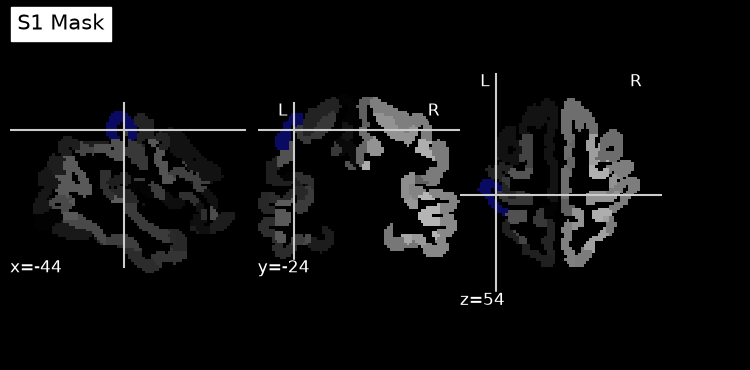

In [32]:
from nilearn.datasets import fetch_atlas_destrieux_2009
from nilearn.image import load_img, index_img, resample_to_img, new_img_like

atlas = fetch_atlas_destrieux_2009()
atlas_img = load_img(atlas.maps)
s1_indices = [
    i for i, lab in enumerate(atlas.labels)
    if "L G_postcentral" in str(lab) and i != 0
]
mask_data = np.isin(atlas_img.get_fdata(), s1_indices).astype("uint8")
s1_mask = new_img_like(atlas_img, mask_data)

# plot the S1 mask over the atlas for visual verification
from nilearn.plotting import plot_roi, plot_anat

plot_roi(s1_mask, bg_img=atlas_img, title="S1 Mask")
# plot_anat(atlas_img, title="Atlas")

## 3. The Decoder

In [7]:
EXTRACTED_DATA_DIR = Path("data/processed_features")


## 3.1 Create the input set.

In [9]:

import joblib
import numpy as np
from pathlib import Path
from neurocisuc.tools.features import fit_masker, extract_run_features

# Setup directories
EXTRACTED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# [Assume subjects, DERIVATIVES, stim_events, tr_by_subject, etc. are loaded as before]

for subject in subjects:
    print(f"Extracting features for {subject}...")

    # Load events for the subject
    events_df, stim_events = load_subject_events(subject)
    
    # Construct the path to the first functional run.
    first_run_path = DERIVATIVES / f"{subject}/ses-{session}/func/{subject}_ses-{session}_task-{task}_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz"

    print(f"Checking first run path: {first_run_path}")
    
    if not first_run_path.exists():
        print(f"First run path does not exist for {subject}")
        continue

    # 1. Fit Masker and Save it
    masker = fit_masker(first_run_path, s1_mask)
    joblib.dump(masker, EXTRACTED_DATA_DIR / f"{subject}_masker.joblib")
    
    feature_rows, labels, groups = [], [], []
    
    # 2. Extract Data
    for run in range(1, n_runs_per_subject + 1):

        # Construct the path to the functional data for the current run.
        func_path = DERIVATIVES / f"{subject}/ses-{session}/func/{subject}_ses-{session}_task-{task}_run-{run}_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz"

        print(f"Checking function path: {func_path}")


        # Check if the functional data path exists; if not, print a warning and skip to the next run.
        if not func_path.exists():
            print(f"Function path does not exist for {subject}, run {run}")
            continue

        # Extract the events for the current run and sort them by onset time.
        run_events = stim_events[(stim_events["subject"] == subject) & (stim_events["run"] == run)].sort_values("onset")
        X_run, y_run = extract_run_features(func_path, run_events, masker, tr_by_subject[subject], hrf_delay=HRF_DELAY, window=WINDOW)
        
        if X_run.size > 0:
            feature_rows.append(X_run)
            labels.extend(y_run)
            groups.extend([run] * len(y_run))

    if feature_rows:
        X_features = np.vstack(feature_rows)
        y = np.asarray(labels)
        groups = np.asarray(groups)
        
        # 3. Save as compressed NumPy array (Much faster and safer than CSV)
        np.savez_compressed(
            EXTRACTED_DATA_DIR / f"{subject}_dataset.npz", 
            X=X_features, y=y, groups=groups
        )
print("Data extraction complete.")

Extracting features for sub-p0001...
Checking first run path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


/Users/brunoleitao/Documents/GitHub/Mapping_Tese/mapping_tese/src/neurocisuc/tools/features.py:15: RuntimeWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  masker.fit(ref_img)


Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-2_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-3_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-4_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Extracting features for sub-p0002...
Checking first run path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


/Users/brunoleitao/Documents/GitHub/Mapping_Tese/mapping_tese/src/neurocisuc/tools/features.py:15: RuntimeWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  masker.fit(ref_img)


Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-2_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-3_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-4_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Data extraction complete.


In [42]:
import joblib
import numpy as np
from pathlib import Path
from neurocisuc.tools.features import fit_masker, extract_run_features, extract_run_multiple_features

# Setup directories
EXTRACTED_DATA_DIR = Path("data/processed_multiple_features")

EXTRACTED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# [Assume subjects, DERIVATIVES, stim_events, tr_by_subject, etc. are loaded as before]

for subject in subjects:
    print(f"Extracting features for {subject}...")

    # Load events for the subject
    events_df, stim_events = load_subject_events(subject)
    
    # Construct the path to the first functional run.
    first_run_path = DERIVATIVES / f"{subject}/ses-{session}/func/{subject}_ses-{session}_task-{task}_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz"

    print(f"Checking first run path: {first_run_path}")
    
    if not first_run_path.exists():
        print(f"First run path does not exist for {subject}")
        continue

    # 1. Fit Masker and Save it
    masker = fit_masker(first_run_path, s1_mask)
    joblib.dump(masker, EXTRACTED_DATA_DIR / f"{subject}_masker.joblib")
    
    feature_rows, labels, groups = [], [], []
    
    # 2. Extract Data
    for run in range(1, n_runs_per_subject + 1):

        # Construct the path to the functional data for the current run.
        func_path = DERIVATIVES / f"{subject}/ses-{session}/func/{subject}_ses-{session}_task-{task}_run-{run}_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz"

        print(f"Checking function path: {func_path}")


        # Check if the functional data path exists; if not, print a warning and skip to the next run.
        if not func_path.exists():
            print(f"Function path does not exist for {subject}, run {run}")
            continue

        # Extract the events for the current run and sort them by onset time.
        run_events = stim_events[(stim_events["subject"] == subject) & (stim_events["run"] == run)].sort_values("onset")
        X_run, y_run = extract_run_multiple_features(func_path, run_events, masker, tr_by_subject[subject], hrf_delay=HRF_DELAY, window=WINDOW)
        
        if X_run.size > 0:
            feature_rows.append(X_run)
            labels.extend(y_run)
            groups.extend([run] * len(y_run))

    if feature_rows:
        X_features = np.vstack(feature_rows)
        y = np.asarray(labels)
        groups = np.asarray(groups)
        
        # 3. Save as compressed NumPy array (Much faster and safer than CSV)
        np.savez_compressed(
            EXTRACTED_DATA_DIR / f"{subject}_dataset.npz", 
            X=X_features, y=y, groups=groups
        )
print("Data extraction complete.")

Extracting features for sub-p0001...
Checking first run path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


/Users/brunoleitao/Documents/GitHub/Mapping_Tese/mapping_tese/src/neurocisuc/tools/features.py:15: RuntimeWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  masker.fit(ref_img)


Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Extracting features for event Forearm at peak volume 11 with volumes [10, 11, 12]
Extracting features for event Arm at peak volume 17 with volumes [16, 17, 18]
Extracting features for event Middle_Finger at peak volume 24 with volumes [23, 24, 25]
Extracting features for event Forearm at peak volume 30 with volumes [29, 30, 31]
Extracting features for event Hand at peak volume 35 with volumes [34, 35, 36]
Extracting features for event Arm at peak volume 42 with volumes [41, 42, 43]
Extracting features for event Forearm at peak volume 47 with volumes [46, 47, 48]
Extracting features for event Middle_Finger at peak volume 53 with volumes [52, 53, 54]
Extracting features for event Arm at peak volume 60 with volumes [59, 60, 61]
Extracting features for event Forearm at peak volume 65 with volumes [64,

/Users/brunoleitao/Documents/GitHub/Mapping_Tese/mapping_tese/src/neurocisuc/tools/features.py:15: RuntimeWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  masker.fit(ref_img)


Checking function path: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
Extracting features for event Forearm at peak volume 11 with volumes [10, 11, 12]
Extracting features for event Arm at peak volume 16 with volumes [15, 16, 17]
Extracting features for event Forearm at peak volume 22 with volumes [21, 22, 23]
Extracting features for event Arm at peak volume 29 with volumes [28, 29, 30]
Extracting features for event Hand at peak volume 35 with volumes [34, 35, 36]
Extracting features for event Arm at peak volume 40 with volumes [39, 40, 41]
Extracting features for event Forearm at peak volume 47 with volumes [46, 47, 48]
Extracting features for event Hand at peak volume 53 with volumes [52, 53, 54]
Extracting features for event Forearm at peak volume 58 with volumes [57, 58, 59]
Extracting features for event Arm at peak volume 65 with volumes [64, 65, 66]
Extracting

In [43]:
print("Data extraction complete.")

# number of datapoints extracted for each subject
print(len(y))


Data extraction complete.
480


## 3.2 Decoding

In [44]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from neurocisuc.decode.linear_svm import evaluate_nested_loro_cv

RESULTS_DIR = Path("results/svm_decoding")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_rows = []

# You can now loop over the saved datasets instead of NIfTI files
for dataset_path in EXTRACTED_DATA_DIR.glob("*_dataset.npz"):
    subject = dataset_path.stem.split("_")[0] # Extracts 'sub-01' from 'sub-01_dataset.npz'
    print(f"Decoding {subject}...")
    
    subject_results_dir = RESULTS_DIR / subject
    subject_results_dir.mkdir(parents=True, exist_ok=True)

    # 1. Load Data and Masker
    data = np.load(dataset_path, allow_pickle=True)
    X_features = data['X']
    y = data['y']
    groups = data['groups']
    
    masker = joblib.load(EXTRACTED_DATA_DIR / f"{subject}_masker.joblib")

    # print(f"Loaded {len(y)} samples for {subject} with {X_features.shape[1]} features.")
    
    unique_classes, counts = np.unique(y, return_counts=True)
    
    # 2. Run Decoding
    try:
        metrics = evaluate_nested_loro_cv(X_features, y, groups, random_seed=RANDOM_SEED)
    except ValueError as e:
        print(f"Skipping {subject}: {e}")
        continue
        
    # 3. Save Voxel Weights for Visualization
    mean_weights = metrics.pop("mean_weights")
    weight_img = masker.inverse_transform(mean_weights)
    weight_img.to_filename(str(subject_results_dir / f"{subject}_svc_weights.nii.gz"))
    
    # 4. Save True/Predicted labels for Confusion Matrices / ROC curves
    y_true = metrics.pop("y_true")
    y_pred = metrics.pop("y_pred")
    np.savez_compressed(
        subject_results_dir / f"{subject}_predictions.npz", 
        y_true=y_true, y_pred=y_pred, classes=unique_classes
    )
    
    # 5. Log Summary Stats
    summary_rows.append({
        "subject": subject,
        "n_samples": len(y),
        "n_voxels": X_features.shape[1],
        "n_classes": len(unique_classes),
        "chance_level": 1.0 / len(unique_classes),
        "samples_per_class": str(dict(zip(unique_classes, counts))),
        **metrics
    })

# Save the final statistical summary as CSV
summary_df = pd.DataFrame(summary_rows).sort_values("subject").reset_index(drop=True)
summary_df.to_csv(RESULTS_DIR / "svm_multi_subject_summary.csv", index=False)
print("Decoding complete. Results and visualization assets stored.")

Decoding sub-p0002...


/Users/brunoleitao/anaconda3/envs/somato-dec/lib/python3.15/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/brunoleitao/anaconda3/envs/somato-dec/lib/python3.15/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/brunoleitao/anaconda3/envs/somato-dec/lib/python3.15/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/brunoleitao/anaconda3/envs/somato-dec/lib/python3.15/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/brunoleitao/anaconda3/envs/somato-dec/lib/python3.15/site-pac

Decoding sub-p0001...
Decoding complete. Results and visualization assets stored.


In [45]:
summary_df

,subject,n_samples,n_voxels,n_classes,chance_level,samples_per_class,mean_accuracy,std_accuracy,mean_balanced_accuracy,std_balanced_accuracy,best_C_per_fold
0,sub-p0001,480,2187,4,0.25,"{np.str_('Arm'): np.int64(168), np.str_('Forea...",0.331250,0.00691,0.329489,0.055643,"[0.001, 0.001, 0.001, 0.001]"
1,sub-p0002,480,2187,4,0.25,"{np.str_('Arm'): np.int64(168), np.str_('Forea...",0.302083,0.05013,0.330729,0.068709,"[0.001, 0.01, 1.0, 0.1]"


In [46]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from neurocisuc.decode.rbf_svm import evaluate_nested_loro_rbf_cv

RESULTS_DIR = Path("results/rbf_svm_decoding")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_rows = []

# You can now loop over the saved datasets instead of NIfTI files
for dataset_path in EXTRACTED_DATA_DIR.glob("*_dataset.npz"):
    subject = dataset_path.stem.split("_")[0] # Extracts 'sub-01' from 'sub-01_dataset.npz'
    print(f"Decoding {subject}...")
    
    subject_results_dir = RESULTS_DIR / subject
    subject_results_dir.mkdir(parents=True, exist_ok=True)

    # 1. Load Data and Masker
    data = np.load(dataset_path, allow_pickle=True)
    X_features = data['X']
    y = data['y']
    groups = data['groups']
    
    masker = joblib.load(EXTRACTED_DATA_DIR / f"{subject}_masker.joblib")

    # print(f"Loaded {len(y)} samples for {subject} with {X_features.shape[1]} features.")
    
    unique_classes, counts = np.unique(y, return_counts=True)
    
    # 2. Run Decoding
    try:
        metrics = evaluate_nested_loro_rbf_cv(X_features, y, groups, random_seed=RANDOM_SEED)
    except ValueError as e:
        print(f"Skipping {subject}: {e}")
        continue

  
    
    # 4. Save True/Predicted labels for Confusion Matrices / ROC curves
    y_true = metrics.pop("y_true")
    y_pred = metrics.pop("y_pred")
    np.savez_compressed(
        subject_results_dir / f"{subject}_predictions.npz", 
        y_true=y_true, y_pred=y_pred, classes=unique_classes
    )
    
    # 5. Log Summary Stats
    summary_rows.append({
        "subject": subject,
        "n_samples": len(y),
        "n_voxels": X_features.shape[1],
        "n_classes": len(unique_classes),
        "chance_level": 1.0 / len(unique_classes),
        "samples_per_class": str(dict(zip(unique_classes, counts))),
        **metrics
    })

# Save the final statistical summary as CSV
summary_df = pd.DataFrame(summary_rows).sort_values("subject").reset_index(drop=True)
summary_df.to_csv(RESULTS_DIR / "svm_multi_subject_summary.csv", index=False)
print("Decoding complete. Results and visualization assets stored.")

Decoding sub-p0002...
Decoding sub-p0001...
Decoding complete. Results and visualization assets stored.


In [47]:
summary_df

,subject,n_samples,n_voxels,n_classes,chance_level,samples_per_class,mean_accuracy,std_accuracy,mean_balanced_accuracy,std_balanced_accuracy,best_params_per_fold
0,sub-p0001,480,2187,4,0.25,"{np.str_('Arm'): np.int64(168), np.str_('Forea...",0.320833,0.069846,0.280134,0.059735,"[{'clf__C': 1.0, 'clf__gamma': 0.0001}, {'clf_..."
1,sub-p0002,480,2187,4,0.25,"{np.str_('Arm'): np.int64(168), np.str_('Forea...",0.310417,0.039253,0.291419,0.052703,"[{'clf__C': 1.0, 'clf__gamma': 0.0001}, {'clf_..."


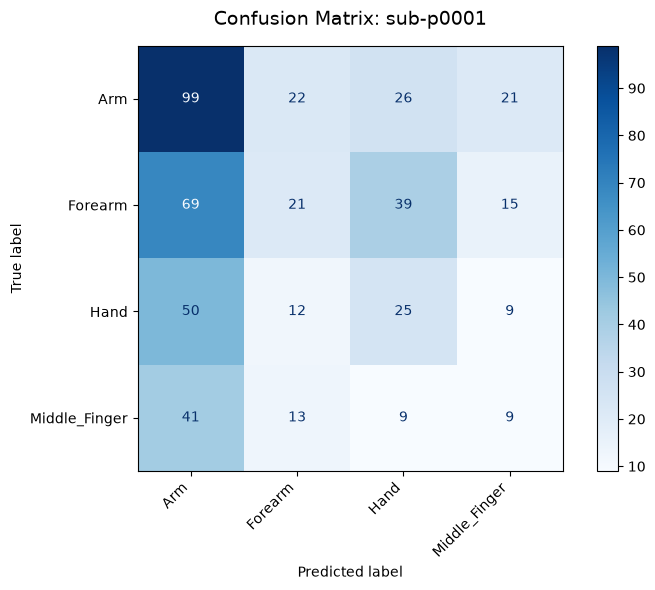

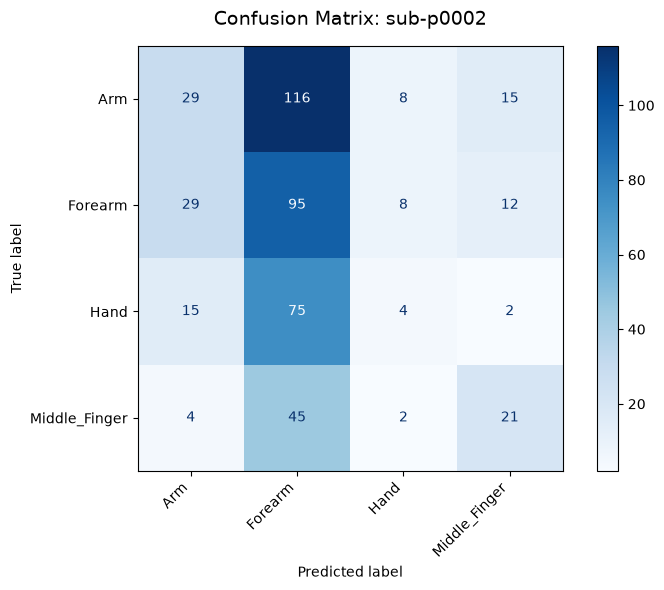

In [48]:
# visualize confusion matrices and ROC curves for each subject
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# Define paths where your predictions were saved
RESULTS_DIR = Path("results/rbf_svm_decoding")
VISUALS_DIR = Path("results/visualizations/confusion_matrices")
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

# Iterate through all saved subject predictions
for pred_file in RESULTS_DIR.rglob("*_predictions.npz"):
    subject = pred_file.stem.split("_")[0]  # e.g., 'sub-01'
    
    # 1. Load the arrays
    data = np.load(pred_file, allow_pickle=True)
    y_true = data["y_true"]
    y_pred = data["y_pred"]
    classes = data["classes"]
    
    # 2. Setup the plot
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # 3. Generate the Confusion Matrix
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, 
        y_pred, 
        labels=classes, 
        cmap="Blues", 
        colorbar=True,
        ax=ax
    )
    
    # 4. Formatting
    ax.set_title(f"Confusion Matrix: {subject}", fontsize=14, pad=15)
    plt.xticks(rotation=45, ha="right")  # Tilt labels if they are long
    plt.tight_layout()
